#### ---> Machine learning follows a rule GIGO - Garbage In, Garbage Out 
----> If we gave the garbage data, then it would produce the garbage data.

In [1]:
import pandas as pd
import numpy as np

## Data Cleaning
1. Importing Dataset
2. Merge Datasets into dataset
3. Identifying the errors
4. Standardize processes
5. scrub for duplicates
6. validate accuracy

In [2]:
data1 = pd.read_csv("E:/AI_ML_Training/AI_ML/raw_materials/IPL2025Batters.csv")
data1

,Player Name,Team,Runs,Matches,Inn,No,HS,AVG,BF,SR,100s,50s,4s,6s
0,Sai Sudharsan,GT,759,15,15,1,108*,54.21,486,156.17,1,6,88,21
1,Surya Kumar Yadav,MI,717,16,16,5,73*,65.18,427,167.91,0,5,69,38
2,Virat Kohli,RCB,657,15,15,3,73*,54.75,454,144.71,0,8,66,19
3,Shubman Gill,GT,650,15,15,2,93*,50.00,417,155.87,0,6,62,24
4,Mitchell Marsh,LSG,627,13,13,0,117,48.23,383,163.70,1,6,56,37
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
151,Khaleel Ahmed,CSK,1,14,2,2,1*,-,2,50.00,0,0,0,0
152,Mohit Sharma,DC,1,8,2,1,1*,1.00,3,33.33,0,0,0,0
153,Donovan Ferreira,DC,1,1,1,0,1,1.00,3,33.33,0,0,0,0
154,Digvesh Singh,LSG,1,13,2,1,1,1.00,3,33.33,0,0,0,0


## Merge Datasets 
**By the Use of Merge Fuction we are merging to different dataset into one**

In [3]:
# Create dataframe 

df1 = pd.DataFrame({"ID": [58, 83, 78, 39, 73, 1,105],
                   "Class": [1, 1, 2, 1, 1, 1,2]})
df1

,ID,Class
0,58,1
1,83,1
2,78,2
3,39,1
4,73,1
5,1,1
6,105,2


In [4]:
df2 = pd.DataFrame({"ID": [58, 83, 78, 39, 73, 1,114],
                   "Name": ["Soumar", "Nishant", "Mahipal", "Vijay", "Shailesh", "Suha", "Meet"]})
df2

,ID,Name
0,58,Soumar
1,83,Nishant
2,78,Mahipal
3,39,Vijay
4,73,Shailesh
5,1,Suha
6,114,Meet


In [5]:
# merging the two dataset on the basis of ID column using "on" parameter
# merge function default merge the dataset into inner manner. So exact matching values of given parameter into "on" parameter will merge and show. 
 
df3 = pd.merge(df1, df2, on = "ID")
df3

,ID,Class,Name
0,58,1,Soumar
1,83,1,Nishant
2,78,2,Mahipal
3,39,1,Vijay
4,73,1,Shailesh
5,1,1,Suha


In [6]:
## Performing left merge by passing parameter how  = 'left'

df3 = pd.merge(df1, df2, how = "left", on = "ID")
df3

,ID,Class,Name
0,58,1,Soumar
1,83,1,Nishant
2,78,2,Mahipal
3,39,1,Vijay
4,73,1,Shailesh
5,1,1,Suha
6,105,2,NaN


In [7]:
## performing Right merge()

df3 = pd.merge(df1, df2, how = 'right', on = "ID")
df3

,ID,Class,Name
0,58,1.0,Soumar
1,83,1.0,Nishant
2,78,2.0,Mahipal
3,39,1.0,Vijay
4,73,1.0,Shailesh
5,1,1.0,Suha
6,114,NaN,Meet


In [8]:
## performing outer merge()

df3 = pd.merge(df1, df2, how = 'outer', on = "ID")
df3

,ID,Class,Name
0,1,1.0,Suha
1,39,1.0,Vijay
2,58,1.0,Soumar
3,73,1.0,Shailesh
4,78,2.0,Mahipal
5,83,1.0,Nishant
6,105,2.0,NaN
7,114,NaN,Meet


In [9]:
## indicator  ---> use to display the information from which dataset the value is taken.

df3 = pd.merge(df1, df2, how = 'outer', on = "ID", indicator = True)
df3

,ID,Class,Name,_merge
0,1,1.0,Suha,both
1,39,1.0,Vijay,both
2,58,1.0,Soumar,both
3,73,1.0,Shailesh,both
4,78,2.0,Mahipal,both
5,83,1.0,Nishant,both
6,105,2.0,NaN,left_only
7,114,NaN,Meet,right_only


In [10]:
## left_index & right_index  ---> use for mapping, 

df3 = pd.merge(df1, df2, how = 'outer', left_index = True, right_index = True, indicator = True)
df3

,ID_x,Class,ID_y,Name,_merge
0,58,1,58,Soumar,both
1,83,1,83,Nishant,both
2,78,2,78,Mahipal,both
3,39,1,39,Vijay,both
4,73,1,73,Shailesh,both
5,1,1,1,Suha,both
6,105,2,114,Meet,both


In [11]:
df4 = pd.DataFrame({"ID": [58, 83, 78, 39, 73, 1,105],
                   "Class": [1, 1, 2, 1, 1, 1,2]},
                  index = [1,2,3,4,5,6,7])
print(df4)
df5 = pd.DataFrame({"ID": [58, 83, 78, 39, 73, 1,114],
                   "Name": ["Soumar", "Nishant", "Mahipal", "Vijay", "Shailesh", "Suha", "Meet"]},
                  index = [11,12,13,14,15,16,17])
print(df5)

    ID  Class
1   58      1
2   83      1
3   78      2
4   39      1
5   73      1
6    1      1
7  105      2
     ID      Name
11   58    Soumar
12   83   Nishant
13   78   Mahipal
14   39     Vijay
15   73  Shailesh
16    1      Suha
17  114      Meet


### Merging through Indexes

In [12]:
## This is the case where we are doing the merge on the basis of left_index and right_index, this mean it will take the indexies of left dataset and right datset 
## and merge the dataset. but here it will not show any result because of the indexes of both datasets are different.

df6 = pd.merge(df4, df5, left_index = True, right_index = True)
df6

,ID_x,Class,ID_y,Name


In [13]:
df7 = pd.DataFrame({"ID": [58, 83, 78, 39, 73, 1,105],
                   "Class": [1, 1, 2, 1, 1, 1,2]},
                  index = [1,2,3,4,5,6,7])
print(df7)
df8 = pd.DataFrame({"ID": [58, 83, 78, 39, 73, 1,114],
                   "Name": ["Soumar", "Nishant", "Mahipal", "Vijay", "Shailesh", "Suha", "Meet"]},
                  index = [1,2,3,4,5,6,7])
print(df8)

    ID  Class
1   58      1
2   83      1
3   78      2
4   39      1
5   73      1
6    1      1
7  105      2
    ID      Name
1   58    Soumar
2   83   Nishant
3   78   Mahipal
4   39     Vijay
5   73  Shailesh
6    1      Suha
7  114      Meet


In [14]:
## This is the Second case where we are merging the dataset using left_index and right_index, and the indexes of both datasets are same so it will show the result

df9 = pd.merge(df7, df8, left_index = True, right_index = True)
df9

,ID_x,Class,ID_y,Name
1,58,1,58,Soumar
2,83,1,83,Nishant
3,78,2,78,Mahipal
4,39,1,39,Vijay
5,73,1,73,Shailesh
6,1,1,1,Suha
7,105,2,114,Meet


In [15]:
df10 = pd.DataFrame({
    'Age': [25, np.nan, 30, 22, np.nan],
    'Score': [85, 90, np.nan, 75, 80],
    'City': ['New York', 'Paris', 'London', np.nan, 'Paris']
})
df10

,Age,Score,City
0,25.0,85.0,New York
1,NaN,90.0,Paris
2,30.0,NaN,London
3,22.0,75.0,NaN
4,NaN,80.0,Paris


In [16]:
df10.isnull()

,Age,Score,City
0,False,False,False
1,True,False,False
2,False,True,False
3,False,False,True
4,True,False,False


In [17]:
df10.isnull().sum()

Age      2
Score    1
City     1
dtype: int64

In [18]:
df10.isnull().sum().sum()

np.int64(4)

In [19]:
df10.notnull()

,Age,Score,City
0,True,True,True
1,False,True,True
2,True,False,True
3,True,True,False
4,False,True,True


In [20]:
df10.notnull().sum()

Age      3
Score    4
City     4
dtype: int64

## Deleting Missing Values

In [21]:
df10_clean_row = df10.dropna() # ---> by default the  "dropna()" work on rows this will delete the whole row if there is any null value.

df10_clean_col = df10.dropna(axis = 1) # ---> by Proving axis = 1 it will work on the columns.

df10_clean_subset = df10.dropna(subset = ['Age']) #  ---> by providing the subset we can drop null values of column

In [22]:
df10_zero = df10.fillna(0)

df10['Age'] = df10['Age'].fillna(df10['Age'].mean())

df10['City'] = df10['City'].fillna(df10['City'].mode()[0])

In [23]:
print(df10_zero)
print(df10['Age'])
print(df10['City'])

    Age  Score      City
0  25.0   85.0  New York
1   0.0   90.0     Paris
2  30.0    0.0    London
3  22.0   75.0         0
4   0.0   80.0     Paris
0    25.000000
1    25.666667
2    30.000000
3    22.000000
4    25.666667
Name: Age, dtype: float64
0    New York
1       Paris
2      London
3       Paris
4       Paris
Name: City, dtype: object


## Time-Series interpolation

In [24]:
df10_fill = df10.ffill()

df10_bfill = df10.bfill()

df10_interp = df10.select_dtypes(include = [np.number]).interpolate()

## Adavanced Machine Learining Imputation

In [25]:
from sklearn.impute import SimpleImputer, KNNImputer

mean_imputer = SimpleImputer(strategy= 'mean') # Strategy --> 'mean', 'median, 'most_frequent', 'constant'
df10[['Age', 'Score']] = mean_imputer.fit_transform(df10[['Age', 'Score']])
print(df10)

# K-Nearest Neighbors imputation based on similar samples
knn_imputer = KNNImputer(n_neighbors= 2)
df10k = knn_imputer.fit_transform(df10[['Age', 'Score']])
print(df10)

         Age  Score      City
0  25.000000   85.0  New York
1  25.666667   90.0     Paris
2  30.000000   82.5    London
3  22.000000   75.0     Paris
4  25.666667   80.0     Paris
         Age  Score      City
0  25.000000   85.0  New York
1  25.666667   90.0     Paris
2  30.000000   82.5    London
3  22.000000   75.0     Paris
4  25.666667   80.0     Paris


# Day 12 work 


In [26]:
df10

,Age,Score,City
0,25.000000,85.0,New York
1,25.666667,90.0,Paris
2,30.000000,82.5,London
3,22.000000,75.0,Paris
4,25.666667,80.0,Paris


In [27]:
df10k

array([[25.        , 85.        ],
       [25.66666667, 90.        ],
       [30.        , 82.5       ],
       [22.        , 75.        ],
       [25.66666667, 80.        ]])

In [29]:
data2 = {
    'Name': ['Alice', 'Bob', 'Alice', 'Alice', 'Charlie'],
    'Age': [25,30,25,26,35],
    'City': ['New York', 'Paris', 'New York', 'London', 'Berlin']
}

df11 = pd.DataFrame(data2)
df11

,Name,Age,City
0,Alice,25,New York
1,Bob,30,Paris
2,Alice,25,New York
3,Alice,26,London
4,Charlie,35,Berlin


In [31]:
# drop_duplicates() --> used to remove the all duplicates and keeps the first occurrence.

df11_no_duplicates = df11.drop_duplicates()
print("1. After removing exact duplicates (keeps first):")
print(df11_no_duplicates)


1. After removing exact duplicates (keeps first):
      Name  Age      City
0    Alice   25  New York
1      Bob   30     Paris
3    Alice   26    London
4  Charlie   35    Berlin


In [33]:
df11_no_duplicates = df11.drop_duplicates(subset = ['Name']) # using "subset" remove duplicates from particular column
print("1. After removing exact duplicates (keeps first):")
print(df11_no_duplicates)

1. After removing exact duplicates (keeps first):
      Name  Age      City
0    Alice   25  New York
1      Bob   30     Paris
4  Charlie   35    Berlin


In [35]:
df11_no_duplicates = df11.drop_duplicates(subset = ['Name'], keep = 'last') # using "keep" remove duplicates all and keep the last one.
print("1. After removing exact duplicates (keeps first):")
print(df11_no_duplicates)

1. After removing exact duplicates (keeps first):
      Name  Age    City
1      Bob   30   Paris
3    Alice   26  London
4  Charlie   35  Berlin


In [37]:
df11_no_duplicates = df11.drop_duplicates(subset = ['Name'], keep = False) # using "keep" drop all rows that have duplicate names.
print("1. After removing exact duplicates (keeps first):")
print(df11_no_duplicates)

1. After removing exact duplicates (keeps first):
      Name  Age    City
1      Bob   30   Paris
4  Charlie   35  Berlin


In [39]:
## DATASET LINK --> "https://www.kaggle.com/c/house-prices-advanced-regression-techniques/data"
train_D = pd.read_csv(r"E:\AI_ML_Training\AI_ML\raw_materials\Day_11\train.csv")
train_D

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125


In [40]:
train_D.shape

(1460, 81)

In [41]:
train_D.head(6)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
5,6,50,RL,85.0,14115,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,MnPrv,Shed,700,10,2009,WD,Normal,143000


## pd.set_option() 

In [50]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

In [43]:
train_D.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [44]:
train_D.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [46]:
train_D.isnull()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,True,True,False,False,False,False,False,False
1,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,True,True,False,False,False,False,False,False
2,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,True,True,False,False,False,False,False,False
3,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,True,True,False,False,False,False,False,False
4,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,True,True,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,

In [51]:
train_D.isnull().sum()

Id                  0
MSSubClass          0
MSZoning            0
LotFrontage       259
LotArea             0
Street              0
Alley            1369
LotShape            0
LandContour         0
Utilities           0
LotConfig           0
LandSlope           0
Neighborhood        0
Condition1          0
Condition2          0
BldgType            0
HouseStyle          0
OverallQual         0
OverallCond         0
YearBuilt           0
YearRemodAdd        0
RoofStyle           0
RoofMatl            0
Exterior1st         0
Exterior2nd         0
MasVnrType        872
MasVnrArea          8
ExterQual           0
ExterCond           0
Foundation          0
BsmtQual           37
BsmtCond           37
BsmtExposure       38
BsmtFinType1       37
BsmtFinSF1          0
BsmtFinType2       38
BsmtFinSF2          0
BsmtUnfSF           0
TotalBsmtSF         0
Heating             0
HeatingQC           0
CentralAir          0
Electrical          1
1stFlrSF            0
2ndFlrSF            0
LowQualFin

In [52]:
import matplotlib.pyplot as plt
import seaborn as sns

<Axes: >

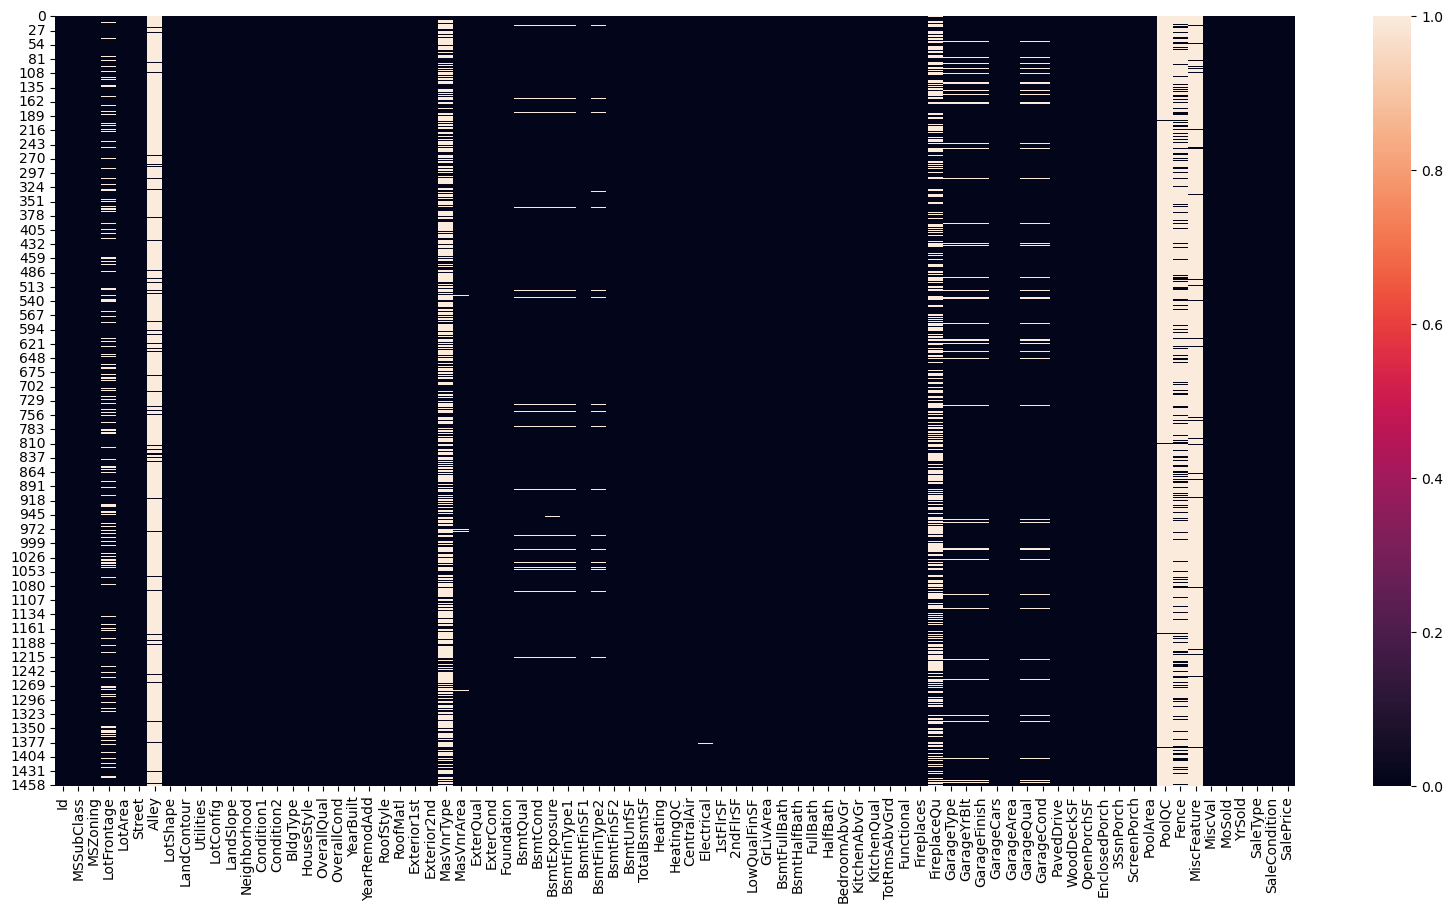

In [55]:
plt.figure(figsize = (20,10))
sns.heatmap(train_D.isnull())

In [57]:
# calculating the null value percentage of all rows.

null_var = train_D.isnull().sum()/train_D.shape[0]*100
null_var

Id                0.000000
MSSubClass        0.000000
MSZoning          0.000000
LotFrontage      17.739726
LotArea           0.000000
Street            0.000000
Alley            93.767123
LotShape          0.000000
LandContour       0.000000
Utilities         0.000000
LotConfig         0.000000
LandSlope         0.000000
Neighborhood      0.000000
Condition1        0.000000
Condition2        0.000000
BldgType          0.000000
HouseStyle        0.000000
OverallQual       0.000000
OverallCond       0.000000
YearBuilt         0.000000
YearRemodAdd      0.000000
RoofStyle         0.000000
RoofMatl          0.000000
Exterior1st       0.000000
Exterior2nd       0.000000
MasVnrType       59.726027
MasVnrArea        0.547945
ExterQual         0.000000
ExterCond         0.000000
Foundation        0.000000
BsmtQual          2.534247
BsmtCond          2.534247
BsmtExposure      2.602740
BsmtFinType1      2.534247
BsmtFinSF1        0.000000
BsmtFinType2      2.602740
BsmtFinSF2        0.000000
B

In [59]:
drop_column = null_var[null_var > 17].keys()
drop_column

Index(['LotFrontage', 'Alley', 'MasVnrType', 'FireplaceQu', 'PoolQC', 'Fence',
       'MiscFeature'],
      dtype='object')

In [66]:
train_D_drop_col = train_D.drop(columns = drop_column)
train_D_drop_col.head()

,Id,MSSubClass,MSZoning,LotArea,Street,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,8450,Pave,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,0,2,2008,WD,Normal,208500
1,2,20,RL,9600,Pave,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,0,5,2007,WD,Normal,181500
2,3,60,RL,11250,Pave,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,0,9,2008,WD,Normal,223500
3,4,70,RL,9550,Pave,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,0,2,2006,WD,Abnorml,140000
4,5,60,RL,14260,Pave,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,0,12,2008,WD,Normal,250000


In [67]:
train_D_drop_col.shape

(1460, 74)

<Axes: >

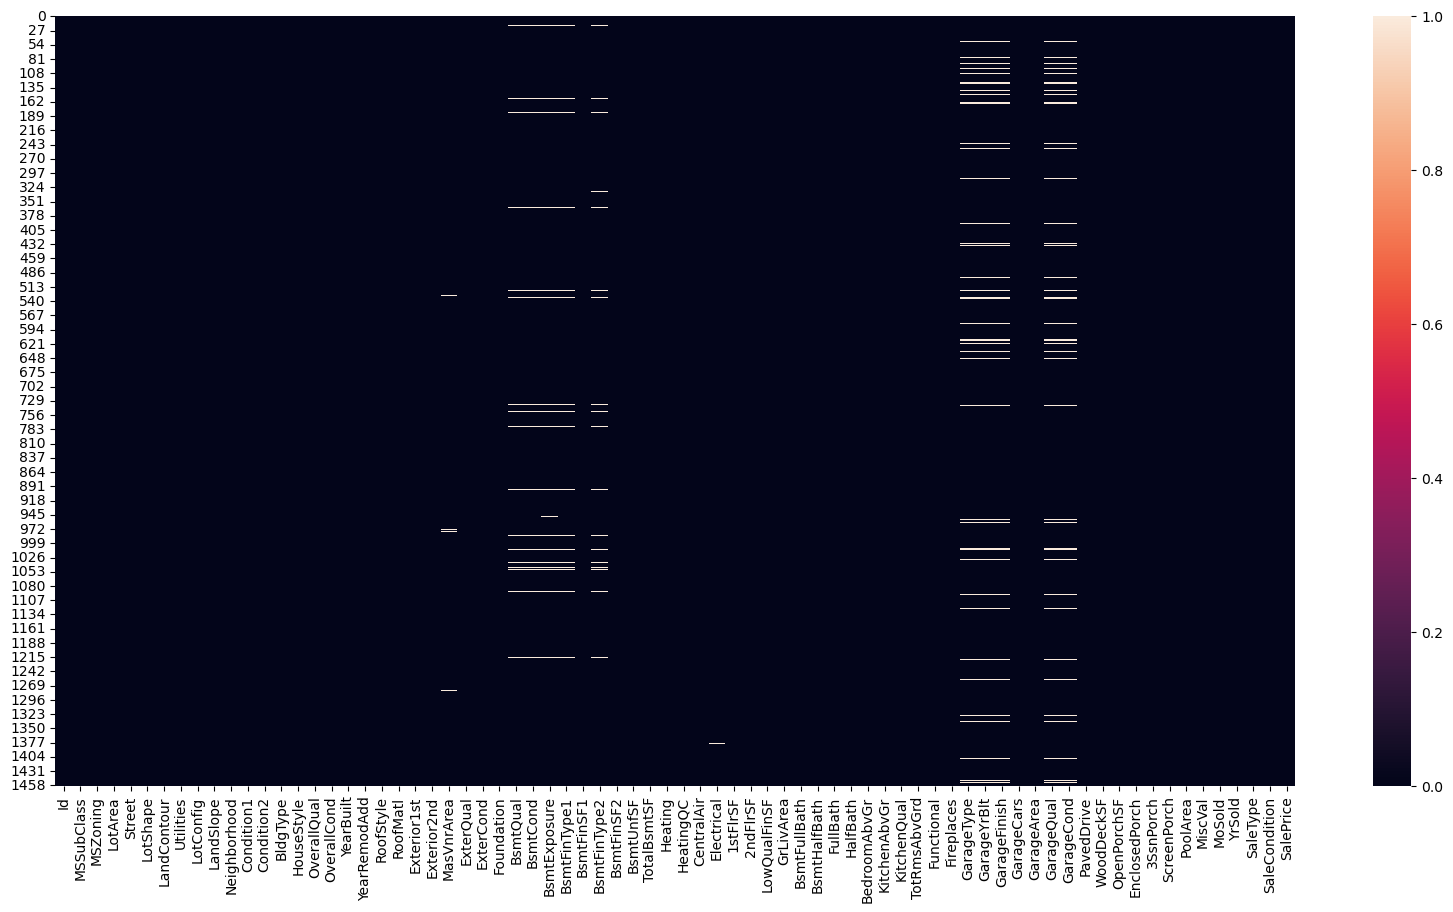

In [68]:
plt.figure(figsize = (20,10))
sns.heatmap(train_D_drop_col.isnull())

In [70]:
train_D_drop_row = train_D_drop_col.dropna()
train_D_drop_row.head()

,Id,MSSubClass,MSZoning,LotArea,Street,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,8450,Pave,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,0,2,2008,WD,Normal,208500
1,2,20,RL,9600,Pave,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,0,5,2007,WD,Normal,181500
2,3,60,RL,11250,Pave,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,0,9,2008,WD,Normal,223500
3,4,70,RL,9550,Pave,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,0,2,2006,WD,Abnorml,140000
4,5,60,RL,14260,Pave,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,0,12,2008,WD,Normal,250000


In [71]:
train_D_drop_row.shape

(1338, 74)

<Axes: >

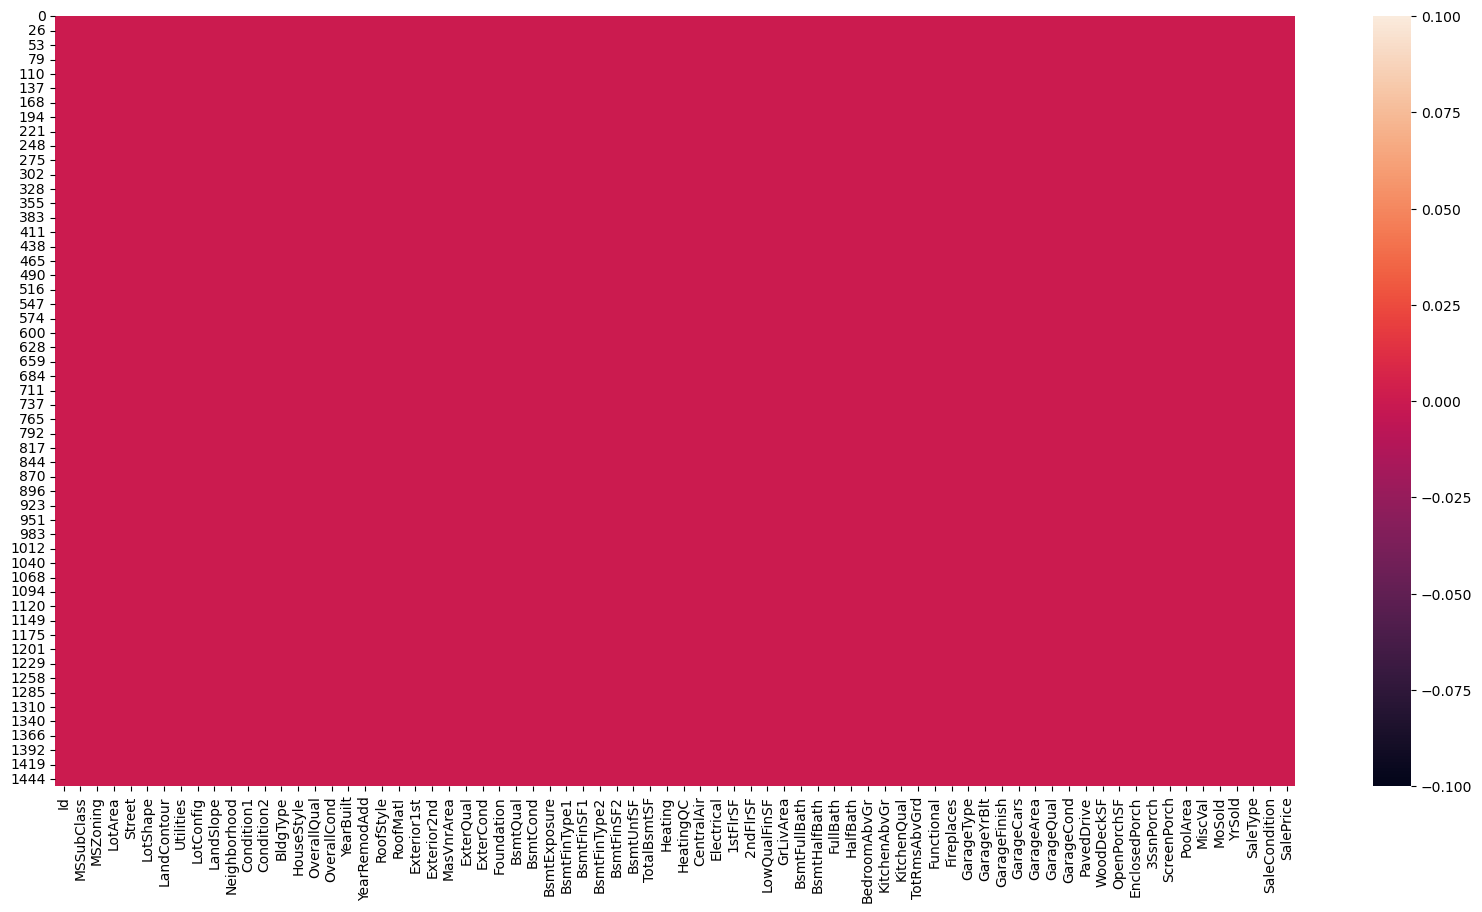

In [72]:
plt.figure(figsize = (20,10))
sns.heatmap(train_D_drop_row.isnull())

In [73]:
train_D_drop_row.isnull().sum().sum()

np.int64(0)

# Numerical Value Data Distribution

In [89]:
train_D_drop_row_num_col_names = train_D_drop_row.select_dtypes(include = ['int64','float64']).columns
train_D_drop_row_num_col_names

Index(['Id', 'MSSubClass', 'LotArea', 'OverallQual', 'OverallCond',
       'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2',
       'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF',
       'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath',
       'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces',
       'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF',
       'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal',
       'MoSold', 'YrSold', 'SalePrice'],
      dtype='object')

C:\Users\Mahipal\AppData\Local\Temp\ipykernel_11280\242025947.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(train_D['MSSubClass'])


<Axes: xlabel='MSSubClass', ylabel='Density'>

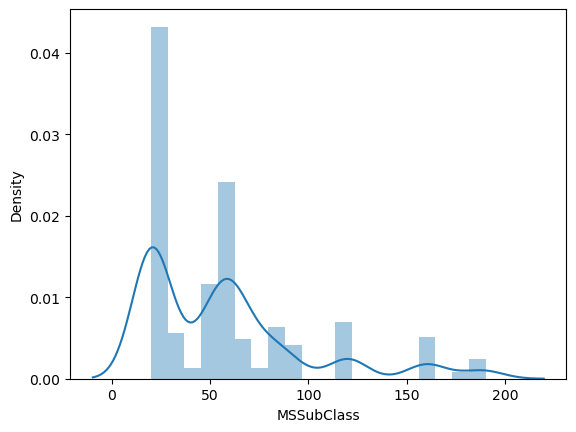

In [90]:
sns.distplot(train_D['MSSubClass'])

C:\Users\Mahipal\AppData\Local\Temp\ipykernel_11280\2679783584.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(train_D_drop_row['MSSubClass'])


<Axes: xlabel='MSSubClass', ylabel='Density'>

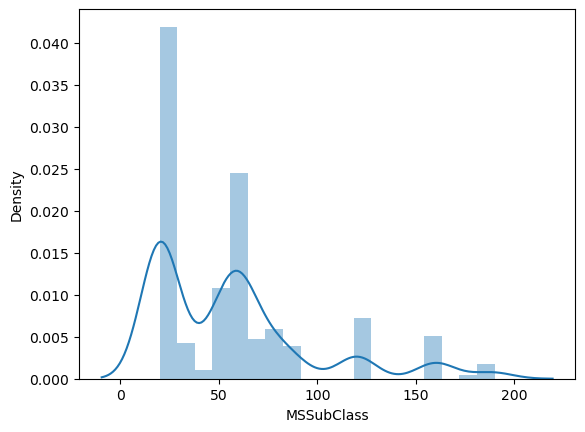

In [77]:
sns.distplot(train_D_drop_row['MSSubClass'])

C:\Users\Mahipal\AppData\Local\Temp\ipykernel_11280\1484217409.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(train_D['MSSubClass'])
C:\Users\Mahipal\AppData\Local\Temp\ipykernel_11280\1484217409.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(train_D_drop_row['MSSubClass'])


<Axes: xlabel='MSSubClass', ylabel='Density'>

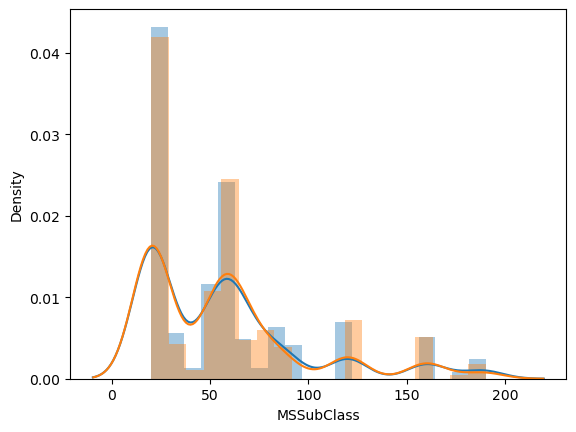

In [91]:
sns.distplot(train_D['MSSubClass'])
sns.distplot(train_D_drop_row['MSSubClass'])

C:\Users\Mahipal\AppData\Local\Temp\ipykernel_11280\583838785.py:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(train_D[name])
C:\Users\Mahipal\AppData\Local\Temp\ipykernel_11280\583838785.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(train_D_drop_row[name])
C:\Users\Mahipal\AppData\Loca

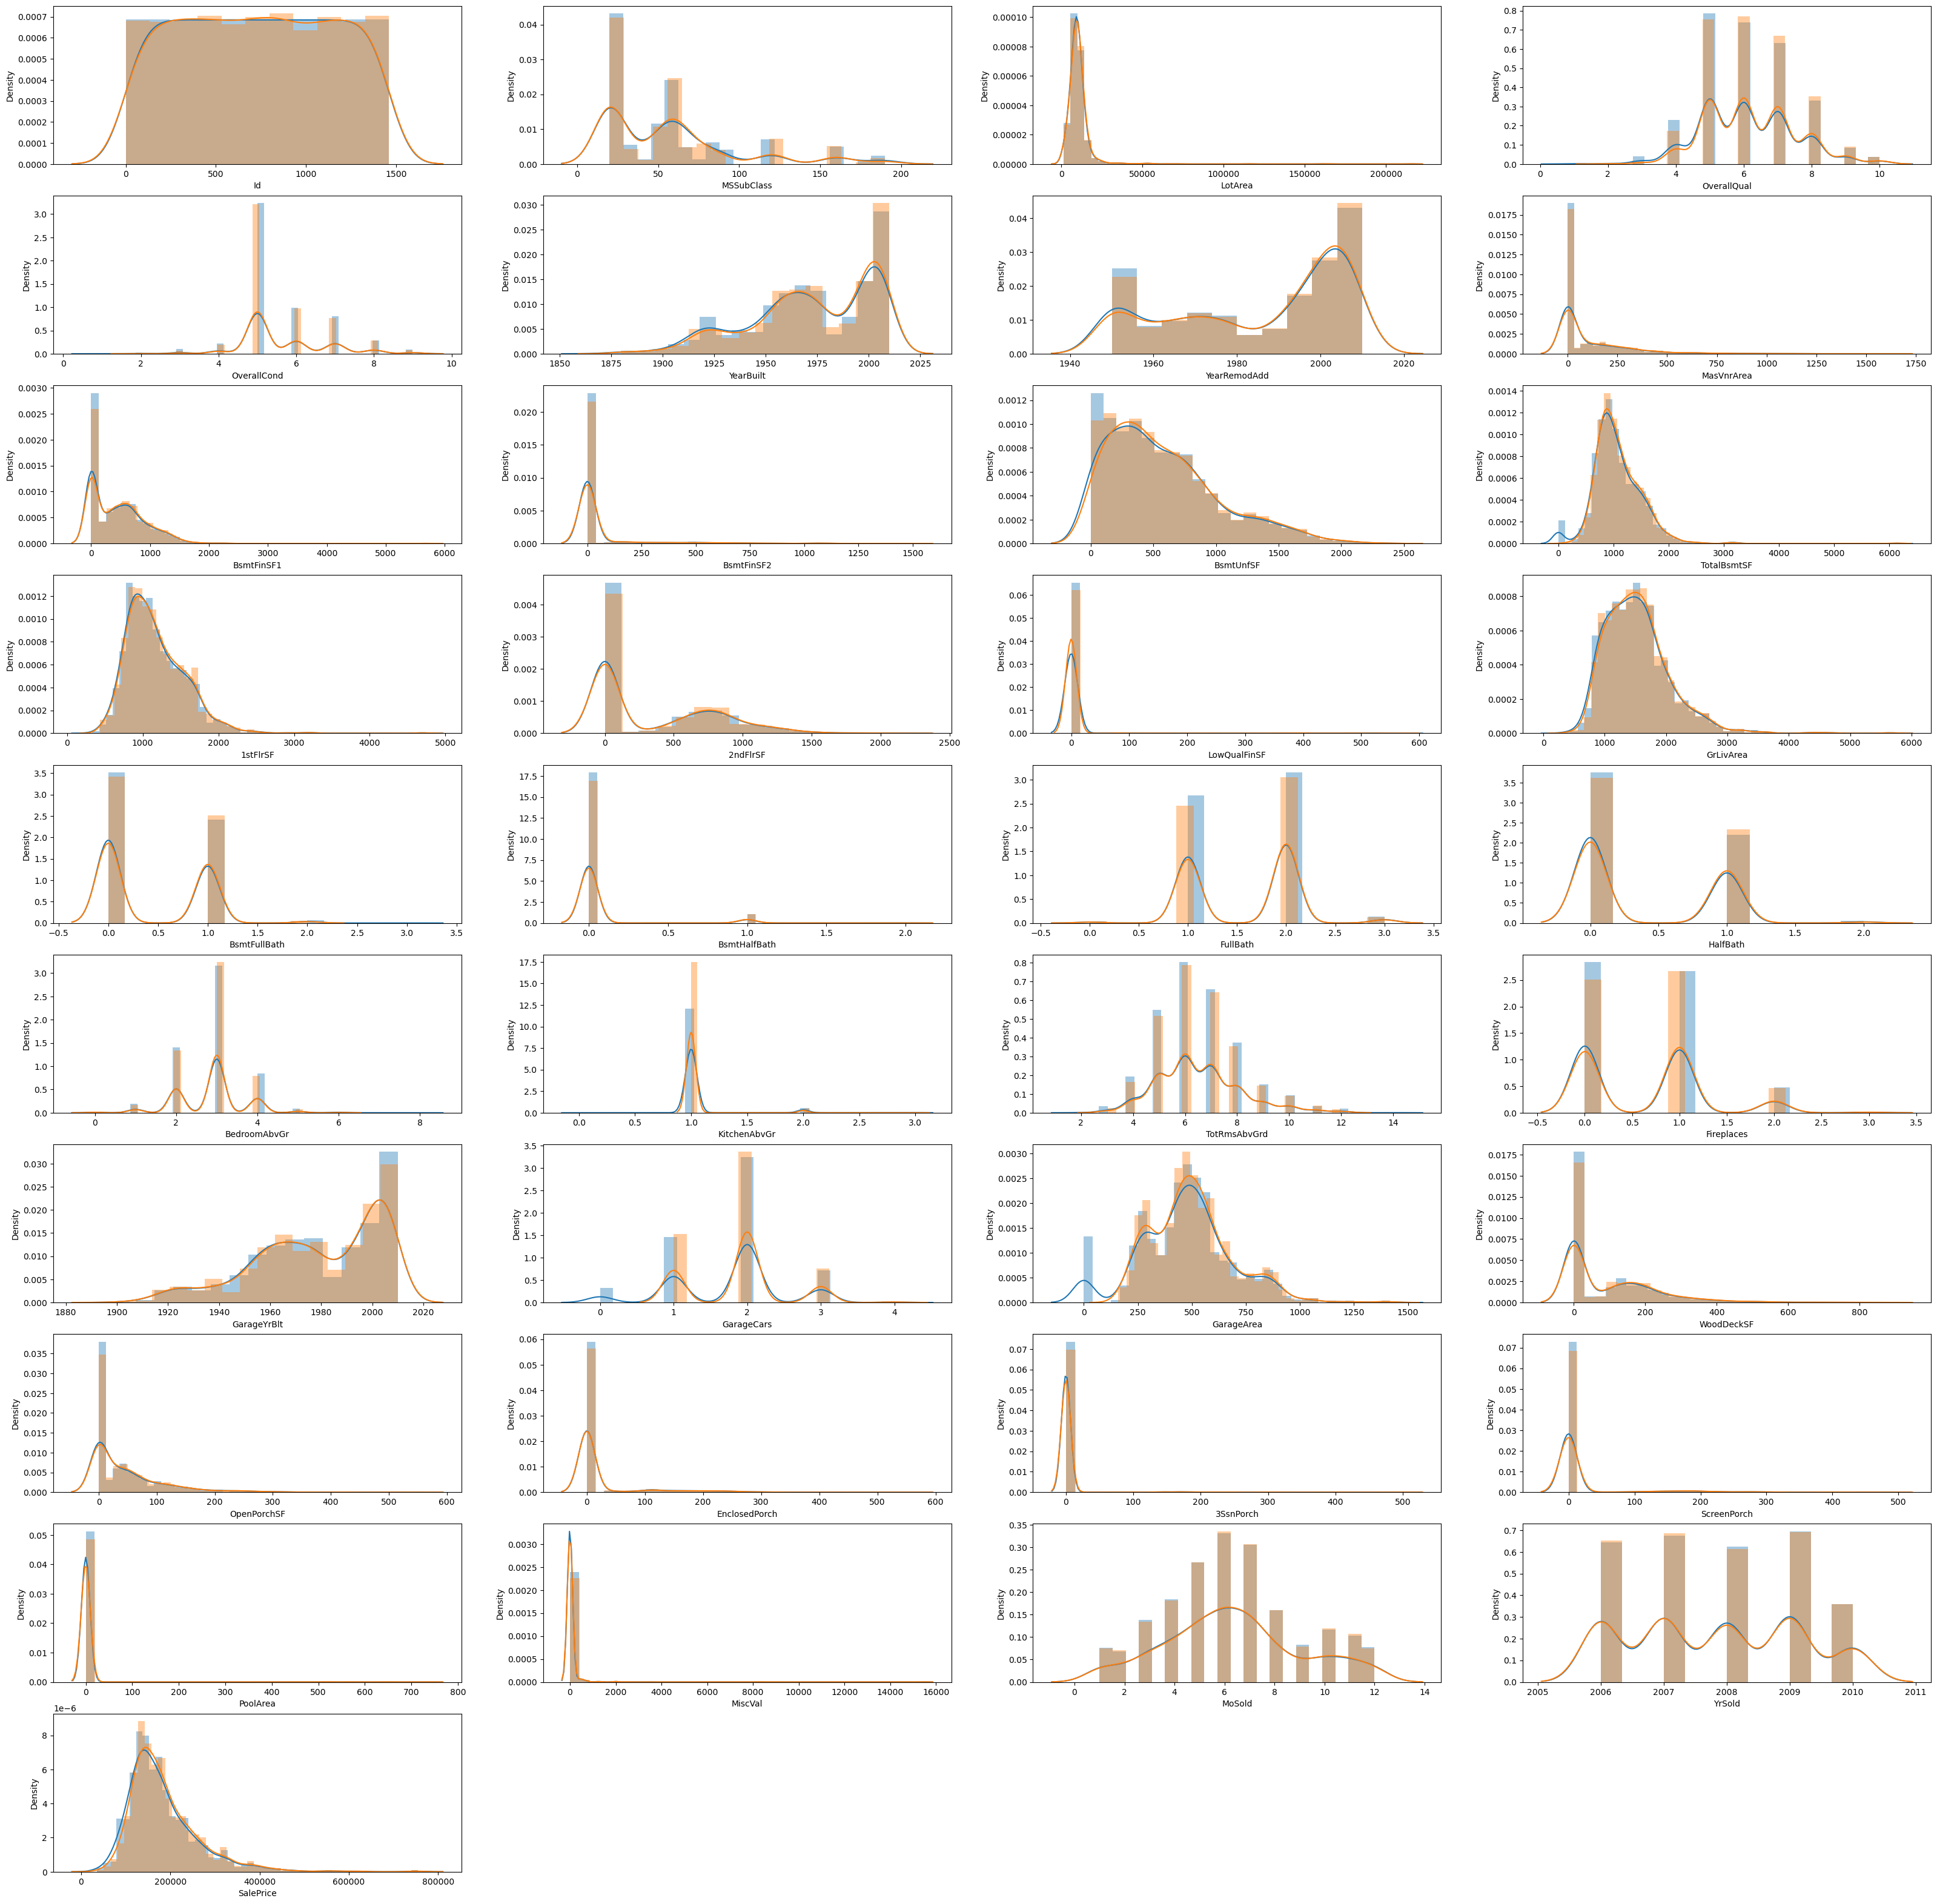

In [92]:
plt.figure(figsize = (40,40))
for i, name in enumerate(train_D_drop_row_num_col_names):
    plt.subplot(10,4,i+1)
    sns.distplot(train_D[name])
    sns.distplot(train_D_drop_row[name])

# Categorical data Distribution


In [88]:
train_D_row_ctg_col_name = train_D_drop_row.select_dtypes(include = ['object']).columns
train_D_row_ctg_col_name

Index(['MSZoning', 'Street', 'LotShape', 'LandContour', 'Utilities',
       'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2',
       'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st',
       'Exterior2nd', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional',
       'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive',
       'SaleType', 'SaleCondition'],
      dtype='object')

In [93]:
train_D['MSZoning'].value_counts()

MSZoning
RL         1151
RM          218
FV           65
RH           16
C (all)      10
Name: count, dtype: int64

In [94]:
train_D['MSZoning'].value_counts()/train_D_drop_row.shape[0]

MSZoning
RL         0.860239
RM         0.162930
FV         0.048580
RH         0.011958
C (all)    0.007474
Name: count, dtype: float64

In [95]:
train_D['MSZoning'].value_counts()/train_D_drop_row.shape[0]*100

MSZoning
RL         86.023916
RM         16.292975
FV          4.857997
RH          1.195815
C (all)     0.747384
Name: count, dtype: float64

In [96]:
train_D_drop_row['MSZoning'].value_counts()/train_D_drop_row.shape[0]*100

MSZoning
RL         79.671151
RM         14.275037
FV          4.633782
RH          0.822123
C (all)     0.597907
Name: count, dtype: float64

In [97]:
pd.concat([train_D['MSZoning'].value_counts()/train_D_drop_row.shape[0]*100, train_D_drop_row['MSZoning'].value_counts()/train_D_drop_row.shape[0]*100],
         axis = 1,
         keys = ['MSZoning_Org', 'MSZoning_Clean'])

,MSZoning_Org,MSZoning_Clean
MSZoning,,
RL,86.023916,79.671151
RM,16.292975,14.275037
FV,4.857997,4.633782
RH,1.195815,0.822123
C (all),0.747384,0.597907


In [98]:
pd.concat([train_D['MSZoning'].value_counts()/train_D.shape[0]*100, train_D_drop_row['MSZoning'].value_counts()/train_D_drop_row.shape[0]*100],
         axis = 1,
         keys = ['MSZoning_Org', 'MSZoning_Clean'])

,MSZoning_Org,MSZoning_Clean
MSZoning,,
RL,78.835616,79.671151
RM,14.931507,14.275037
FV,4.452055,4.633782
RH,1.095890,0.822123
C (all),0.684932,0.597907


In [106]:
def categorical_var_dist(var):
    return pd.concat([train_D[var].value_counts()/train_D.shape[0]*100, train_D_drop_row[var].value_counts()/train_D_drop_row.shape[0]*100],
         axis = 1,
         keys = [var+'_Org', var+'_Clean'])


In [107]:
categorical_var_dist('Street')

,Street_Org,Street_Clean
Street,,
Pave,99.589041,99.626308
Grvl,0.410959,0.373692


In [111]:
for name in train_D_row_ctg_col_name:
    print("="*50)
    print(f"columns --> {name}")
    print("="*50)
    print(categorical_var_dist(name), "\n")

columns --> MSZoning
          MSZoning_Org  MSZoning_Clean
MSZoning                              
RL           78.835616       79.671151
RM           14.931507       14.275037
FV            4.452055        4.633782
RH            1.095890        0.822123
C (all)       0.684932        0.597907 

columns --> Street
        Street_Org  Street_Clean
Street                          
Pave     99.589041     99.626308
Grvl      0.410959      0.373692 

columns --> LotShape
          LotShape_Org  LotShape_Clean
LotShape                              
Reg          63.356164       61.958146
IR1          33.150685       34.304933
IR2           2.808219        2.989537
IR3           0.684932        0.747384 

columns --> LandContour
             LandContour_Org  LandContour_Clean
LandContour                                    
Lvl                89.794521          90.134529
Bnk                 4.315068           3.886398
HLS                 3.424658           3.587444
Low                 2.465753  